# A3: classificador com CNN pré-treinada (EfficientNet-B0 congelada)

Notebook fino: ele chama as mesmas classes do pacote `visaocomp` que o `make run-a3`. Toda a lógica está em `src/visaocomp/a3/`.

**Requisitos**
- Memória: cerca de 2 GB de RAM para o treino com lote de 32; o corpo congelado não guarda gradientes. Se faltar memória, reduza `batch_size` em `configs/a3.yaml`.
- Dispositivo: GPU do Colab (T4), Apple MPS ou CPU, escolhido automaticamente.
- Disco: cerca de 1,5 GB para o dataset extraído (`make data`).
- Tempo: cerca de 2 minutos no Apple M5 (MPS), medido. Na T4 do Colab não foi medido.
- Rede: só na primeira vez (dataset do Kaggle e os pesos do ImageNet, 20 MB).

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/lararli/ml-visao-computacional.git"  # o repositório da entrega; no Colab, esta célula clona e instala

if IN_COLAB and not Path("pyproject.toml").exists():
    assert REPO_URL, "preencha REPO_URL"
    !git clone {REPO_URL} repo
    %cd repo
    %pip install -q -e .

# sobe até a pasta que tem o pyproject.toml, para os caminhos relativos funcionarem
root = Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)
sys.path.insert(0, str(root / "src"))
root

PosixPath('.')

## 1. Dados (a mesma ingestão do `make data`, idempotente)

In [2]:
from visaocomp.config import load_data_config
from visaocomp.data import DataIngestor
from visaocomp.log import configure_logging
from visaocomp.paths import data_dir

configure_logging()
DataIngestor(load_data_config(), data_dir(), root / "outputs").run()

23:58:11 INFO visaocomp.data.ingest: ingestão: início, 3 fontes, dados em ./data.nosync


23:58:11 INFO visaocomp.data.sources: ads16: já existe e passa no checksum (3429 arquivos)


23:58:12 INFO visaocomp.data.sources: images_dataset: já existe e passa no checksum (3606 arquivos)


23:58:12 INFO visaocomp.data.sources: covid_xray: já existe e passa no checksum (5228 arquivos)


23:58:13 INFO visaocomp.catalog: catálogo catalog.duckdb: schemas bronze, silver, gold


23:58:13 INFO visaocomp.data.ingest: ingestão: fim, 0 baixadas, 3 puladas, 12263 arquivos; manifesto ./outputs/20261013-025813-data/manifest.json


PosixPath('./outputs/20261013-025813-data/manifest.json')

## 2. Treino e avaliação

Roda a A3 (`A3Pipeline`) só se ainda não existe um run em `outputs/`. Troque `FORCE_RUN` para `True` para treinar de novo. Um run nunca sobrescreve o anterior.

In [3]:
from visaocomp.a3.cli import run_a3
from visaocomp.run import latest_manifest

FORCE_RUN = False
manifest = latest_manifest(root / "outputs", "a3")
if FORCE_RUN or manifest is None:
    run_a3()
    manifest = latest_manifest(root / "outputs", "a3")
a3_dir = root / "outputs" / manifest["run_id"] / "a3"
a3_dir

PosixPath('./outputs/20261013-003548-a3/a3')

## 3. Resultados (lidos de `metrics.json`)

In [4]:
import json

import pandas as pd

metrics = json.loads((a3_dir / "metrics.json").read_text(encoding="utf-8"))
print(f"accuracy global (teste): {metrics['accuracy_global']:.4f}")
print(f"accuracy balanceada:     {metrics['balanced_accuracy']:.4f}")
print(f"baseline (classe mais comum): {metrics['baseline']['accuracy']:.4f}")
pd.DataFrame(metrics["per_class"]).T

accuracy global (teste): 0.9848
accuracy balanceada:     0.9899
baseline (classe mais comum): 0.2386


,n,correct,accuracy,precision,f1
bike,55.0,52.0,0.945455,0.981132,0.962963
cars,63.0,62.0,0.984127,0.953846,0.968750
cats,30.0,30.0,1.000000,1.000000,1.000000
dogs,30.0,30.0,1.000000,1.000000,1.000000
flowers,32.0,32.0,1.000000,1.000000,1.000000
horses,27.0,27.0,1.000000,1.000000,1.000000
human,27.0,27.0,1.000000,1.000000,1.000000


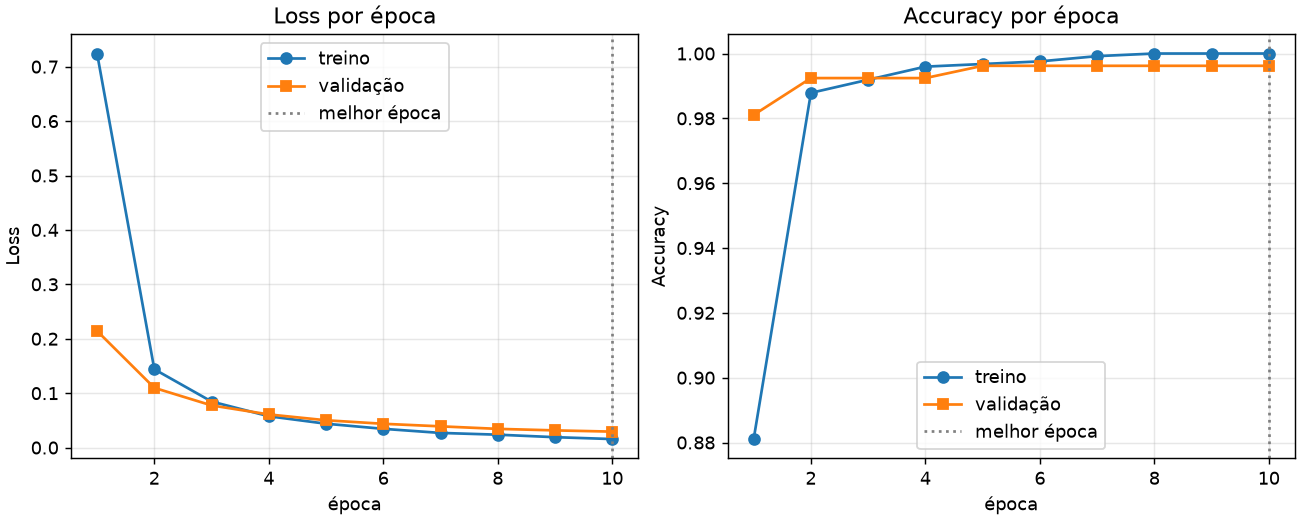

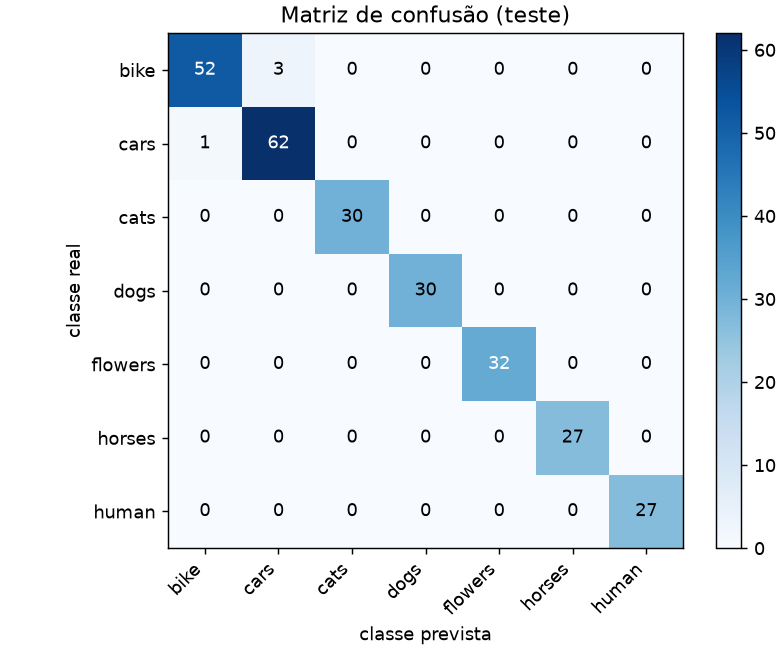

In [5]:
from IPython.display import Image, display

display(Image(filename=str(a3_dir / "curves.png")))
display(Image(filename=str(a3_dir / "confusion.png")))

## 4. Texto da análise (R03, R04 e R05), gerado do mesmo `metrics.json`

In [6]:
from IPython.display import Markdown

Markdown((root / "reports" / "sections" / "a3.md").read_text(encoding="utf-8"))

# A3: classificador com CNN pré-treinada

Seção gerada por `scripts/run_a3.py` a partir de `outputs/20261013-003548-a3/a3/metrics.json`. Todos os números vêm desse arquivo. Não edite à mão: rode `make run-a3`.

Classes do dataset: bike, cars, cats, dogs, flowers, horses, human.

## Resultado do treino (R01 e R02)

Carregamos a EfficientNet-B0 do torchvision com os pesos `IMAGENET1K_V1`, congelamos o corpo (nenhum parâmetro dele tem gradiente) e trocamos o classification head por uma camada linear nova de 1.280 entradas e 7 saídas, uma por classe. Dos 4,0 milhões de parâmetros do modelo, só 8.967 são treinados. É feature extraction: um treino só, 10 épocas, Adam com lr 0,001, lote de 32, em `mps`, 86 segundos de treino.

Os dados: 1.803 imagens lidas, 39 idênticas removidas (mesmo sha256) e 0 ilegíveis puladas, sobrando 1.764. O split é estratificado, seed 42: 1.236 para treino, 264 para validação e 264 para teste. A melhor época pela validação foi a 10 (accuracy de validação 99,6%). O teste foi usado uma vez, com esse checkpoint.

**Accuracy global no teste: 98,5%.** Accuracy balanceada (média das classes): 99,0%. F1 macro: 99,0%. O baseline que prevê sempre a classe mais comum do treino (cars) acerta 23,9% no teste.

| Classe | Imagens no teste | Acertos | Accuracy | Precision | F1 |
|---|---|---|---|---|---|
| bike | 55 | 52 | 94,5% | 98,1% | 96,3% |
| cars | 63 | 62 | 98,4% | 95,4% | 96,9% |
| cats | 30 | 30 | 100,0% | 100,0% | 100,0% |
| dogs | 30 | 30 | 100,0% | 100,0% | 100,0% |
| flowers | 32 | 32 | 100,0% | 100,0% | 100,0% |
| horses | 27 | 27 | 100,0% | 100,0% | 100,0% |
| human | 27 | 27 | 100,0% | 100,0% | 100,0% |

As classes mais difíceis foram bike (94,5%) e cars (98,4%). Trocas mais frequentes: 3 imagens de bike previstas como cars; 1 imagem de cars prevista como bike.

Curvas de loss e accuracy por época: `outputs/20261013-003548-a3/a3/curves.png`. Matriz de confusão: `outputs/20261013-003548-a3/a3/confusion.png`.

## Estratégias de augmentation propostas (R03)

O treino acima não usa augmentation: só resize para o lado menor, recorte central e a normalização do ImageNet (média e desvio ficam dentro do modelo). O PD pede propor, não testar. As propostas abaixo vêm do que as imagens têm: bike e cars são cenas de rua em 640x480 (o objeto ocupa uma parte pequena da foto), cats, dogs e horses são fotos de animais em ambientes variados, flowers são recortes de 128x128 pixels (ampliados para 224), e human são pessoas de corpo inteiro, muitas vestidas para montaria. Começaríamos pelas classes com mais erro: bike (94,5%) e cars (98,4%).

### Flip horizontal
- Por que ajuda: nenhum objeto do dataset tem um lado fixo. Um gato, um cavalo ou um carro espelhado continua sendo da mesma classe, e o flip dobra as poses vistas sem nenhuma imagem nova.
- Pode distorcer: cars, porque placas e letreiros ficam escritos ao contrário, o que nunca ocorre numa foto real; bike, porque a corrente e os pedais passam para o lado oposto. A forma geral não muda, então o risco é pequeno.

### Rotação leve (até cerca de 15 graus)
- Por que ajuda: fotos feitas na mão saem inclinadas, principalmente de cats, dogs e bike. A rotação leve ensina o modelo a ignorar isso.
- Pode distorcer: horses e human, porque aparecem em pé e com o horizonte reto; rotações grandes criam poses que quase não existem nos dados. flowers, porque a imagem tem só 128x128 pixels e os cantos vazios criados pela rotação ocupam uma parte grande dela.

### Recorte aleatório com resize (RandomResizedCrop)
- Por que ajuda: obriga o modelo a reconhecer a classe por partes do objeto (a cabeça do cavalo, a roda da bicicleta), e não por uma única posição.
- Pode distorcer: bike e cars, porque o objeto é pequeno numa cena de rua e um recorte pode deixar só a rua, com o rótulo da classe errado. human, porque muitas dessas pessoas aparecem ao lado de cavalos, e um recorte que tira o corpo inteiro tira também a pista que separa human de horses. flowers, porque recortar uma imagem de 128x128 e ampliar perde ainda mais detalhe.

### Color jitter (brilho, contraste e saturação)
- Por que ajuda: a luz muda muito entre as fotos, e várias fotos de bike são escuras. Variar brilho e contraste torna o modelo menos dependente da iluminação.
- Pode distorcer: flowers, porque a cor (rosa, laranja, roxo) é a pista principal da classe e uma mudança de matiz cria flores de cor irreal; usar só brilho e contraste nessa classe. horses, porque a cor da pelagem varia dentro da classe e uma mudança forte de matiz cria cavalos de cor impossível.

### Conversão aleatória para grayscale (probabilidade baixa)
- Por que ajuda: força o modelo a usar forma e textura, e não só cor. Serve bem a cars e bike, onde a cor do objeto não define a classe.
- Pode distorcer: flowers, porque tira a cor, que é a pista principal; e cats, dogs e horses, porque parte da diferença entre fotos está na pelagem. Por isso a probabilidade deveria ser baixa (por exemplo 0,1).

### Variação de escala (resize aleatório com crop e treino multi-scale)
- Por que ajuda: os tamanhos originais vão de 128x128 (flowers) a 640x480 (bike e cars). O modelo vê o objeto em escalas diferentes, como acontece em uso real.
- Pode distorcer: flowers, porque já são ampliadas de 128 para 224 pixels e ampliar mais deixa a imagem borrada; e bike e cars, porque reduzir demais deixa o objeto, que já é pequeno, com poucos pixels.

## Feature extraction ou fine-tuning (R04)

**Feature extraction** congela o corpo e treina só a cabeça. **Fine-tuning** também atualiza parte ou todo o corpo, com passo de atualização menor nas camadas já treinadas. A escolha depende de dois fatores: o tamanho do dataset e o quanto o domínio se parece com aquele em que o modelo foi pré-treinado (o ImageNet).

- Dataset pequeno e domínio parecido: feature extraction. É o nosso caso. Temos 1.236 imagens de treino e 7 classes, de objetos comuns (gatos, cachorros, carros e bicicletas têm muitas classes no ImageNet). Os parâmetros do corpo já extraem bem esses objetos, e treinar só 8.967 parâmetros com 1.236 imagens quase não tem risco de overfitting. O resultado confirma: 98,5% no teste, contra 23,9% do baseline.
- Dataset pequeno e domínio diferente: feature extraction das camadas intermediárias, ou fine-tuning só das últimas camadas com passo bem pequeno. Atualizar o corpo inteiro com poucas imagens decora o treino.
- Dataset grande e domínio parecido: fine-tuning traz ganho pequeno e custa mais; vale se a diferença de accuracy compensar o tempo.
- Dataset grande e domínio diferente: fine-tuning completo. É o caso de radiografias de tórax (A4) e de imagens aéreas (A1), onde o ImageNet não tem nada parecido e as características do corpo congelado servem pouco.

Na aula 4, o professor mostrou o mesmo trade-off com um ViT: com o corpo congelado, cerca de 91% de accuracy contra 96% do fine-tuning completo, com cerca de 20 segundos a menos de treino. Para o nosso dataset, o fine-tuning só seria o próximo passo se o erro que sobrou (3 imagens de bike previstas como cars; 1 imagem de cars prevista como bike) se concentrasse em classes que o corpo congelado não separa.

## Escolha do modelo pré-treinado (R05)

Escolhemos a EfficientNet-B0 (`IMAGENET1K_V1`) por três razões.

1. **Capacidade do Colab T4.** A T4 tem 16 GB de memória de vídeo. A EfficientNet-B0 tem 4,0 milhões de parâmetros com a nossa cabeça de 7 classes (5,3 milhões com a cabeça original de 1.000 classes do ImageNet) e 0,39 GFLOPs por imagem, contra 25,6 milhões e 4,1 da ResNet-50 (valores do torchvision). Com o corpo congelado, o treino não guarda as ativações para o backward: só a cabeça é treinada, então o consumo se parece com o da inferência. Aqui o treino inteiro levou 86 segundos com lote de 32, num computador local.
2. **Número de classes.** São 7 classes. A cabeça é uma camada linear de 1.280 por 7, com 8.967 parâmetros. Para tão poucas classes não faz falta um corpo grande: o que importa é a qualidade das características, e a EfficientNet-B0 chega a 77,7% de accuracy top-1 no ImageNet, contra 76,1% da ResNet-50 nos pesos `IMAGENET1K_V1`.
3. **Domínio.** Os objetos do dataset são comuns no ImageNet, então os pesos pré-treinados servem sem adaptação do corpo. Para um domínio distante (A4, radiografias) a escolha seria outra: um modelo maior e fine-tuning.

A cabeça é pequena e o corpo é leve, então o mesmo código roda na T4 do Colab e no Apple M5 (MPS).
